# 01 — Análise exploratória (EDA) e formulação de hipóteses
**Tech Challenge Fase 3 — Predição e Inteligência Analítica para Alfabetização no Brasil**

Objetivo: entender o comportamento da camada **Gold** (Fase 2), identificar padrões e formular as hipóteses que orientam a modelagem.

In [ ]:
!unzip -q tech-challenge-fase3.zip
%cd tech-challenge-fase3
!pip install -q shap          # opcional: habilita o gráfico SHAP
!python -m src.run_pipeline   # ~6 min; use --quick para ~1,5 min

/content/tech-challenge-fase3
[21:01:41] Gold carregada: 144 linhas, 25 UFs
[21:01:43] EDA e testes de hipótese concluídos
[21:01:43] [estrutural] n=144 | prevalência classe 1 = 0.65 | repetições = 5
[21:01:45]    baseline_dummy         AUC=0.312±0.071 (2s)
[21:01:54]    regressao_logistica    AUC=0.511±0.076 (9s)
[21:02:55]    random_forest          AUC=0.554±0.082 (61s)
[21:03:47]    gradient_boosting      AUC=0.571±0.068 (52s)
[21:03:47] [temporal] n=74 | prevalência classe 1 = 0.66 | repetições = 5
[21:03:49]    baseline_dummy         AUC=0.309±0.055 (2s)
[21:03:59]    regressao_logistica    AUC=0.817±0.015 (10s)
[21:04:58]    random_forest          AUC=0.793±0.019 (60s)
[21:05:51]    gradient_boosting      AUC=0.790±0.027 (52s)
[21:05:51] [temporal_parcimonioso] n=74 | prevalência classe 1 = 0.66 | repetições = 5
[21:05:52]    baseline_dummy         AUC=0.309±0.055 (1s)
[21:05:58]    regressao_logistica    AUC=0.665±0.101 (6s)
[21:05:58] [vazamento_demo] n=144 | prevalência classe

In [ ]:
import sys, json
sys.path.append("..")            # raiz do repositório
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
from src.config import *
from src.preprocessing.load import load_gold

def mostrar_imagem(nome, largura=9):
    img = mpimg.imread(IMAGES / nome)
    h = largura * img.shape[0] / img.shape[1]
    fig = plt.figure(figsize=(largura, h)); plt.imshow(img); plt.axis("off")

gold, qualidade = load_gold()
print(json.dumps(qualidade, indent=2, ensure_ascii=False))

{
  "linhas": 144,
  "colunas": 30,
  "anos": [
    2023,
    2024
  ],
  "ufs": 25,
  "redes": [
    2,
    3,
    5
  ],
  "duplicatas_chave": 0,
  "nulos_por_coluna": {
    "var_taxa_pp_2023_2024": 74,
    "var_media_2023_2024": 74,
    "proporcao_aluno_nivel_0": 70,
    "proporcao_aluno_nivel_1": 70,
    "proporcao_aluno_nivel_2": 70,
    "proporcao_aluno_nivel_3": 70,
    "proporcao_aluno_nivel_4": 70,
    "proporcao_aluno_nivel_5": 70,
    "proporcao_aluno_nivel_6": 70,
    "proporcao_aluno_nivel_7": 70,
    "proporcao_aluno_nivel_8": 70
  },
  "linhas_com_distribuicao_niveis": 74,
  "soma_niveis_min_max": [
    99.97999999999999,
    100.02000000000001
  ]
}


In [ ]:
gold.groupby(["ano", "rede_descricao"]).taxa_alfabetizacao.describe().round(2)

count   mean    std    min    25%    50%    75%    max
ano  rede_descricao                                                                        
2023 Estadual                         22.0  57.89  14.52  35.31  44.18  57.86  70.20  80.29
     Municipal                        24.0  54.03  12.52  30.57  46.68  52.32  62.42  84.49
     Pública (estadual + municipal)   24.0  54.25  12.37  31.30  46.56  52.34  61.89  84.46
2024 Estadual                         24.0  60.13  15.49  34.46  46.47  58.74  74.08  86.21
     Municipal                        25.0  56.30  12.09  35.96  48.16  56.01  62.56  85.35
     Pública (estadual + municipal)   25.0  56.61  11.95  35.96  48.63  55.96  62.02  85.31

In [ ]:
pub = gold[gold.rede == 5]
disp = pub.groupby("ano").taxa_alfabetizacao.agg(["count", "mean", "min", "max"]).round(1)
disp["amplitude_pp"] = (disp["max"] - disp["min"]).round(1)
disp["ufs_abaixo_50"] = pub.groupby("ano").taxa_alfabetizacao.apply(lambda s: int((s < LIMIAR_ALFABETIZACAO).sum()))
disp

,count,mean,min,max,amplitude_pp,ufs_abaixo_50
ano,,,,,,
2023,24,54.3,31.3,84.5,53.2,8
2024,25,56.6,36.0,85.3,49.3,8


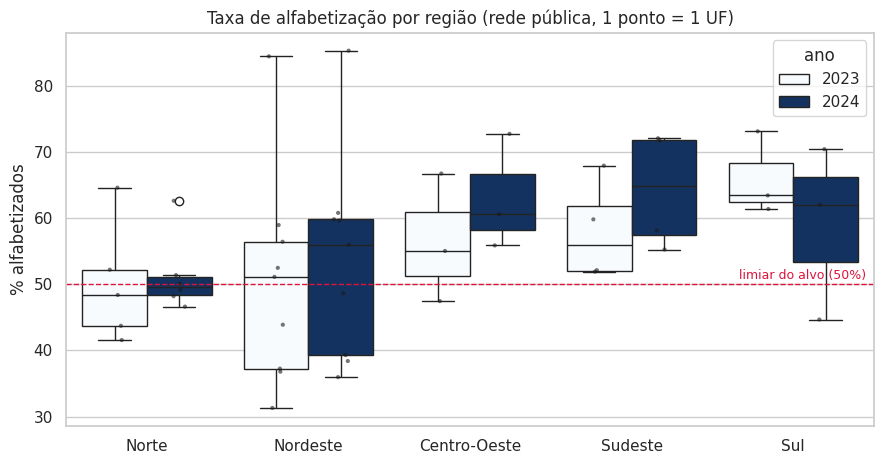

In [ ]:
from src.visualization import plots
plots.fig_regioes(gold, save=None)

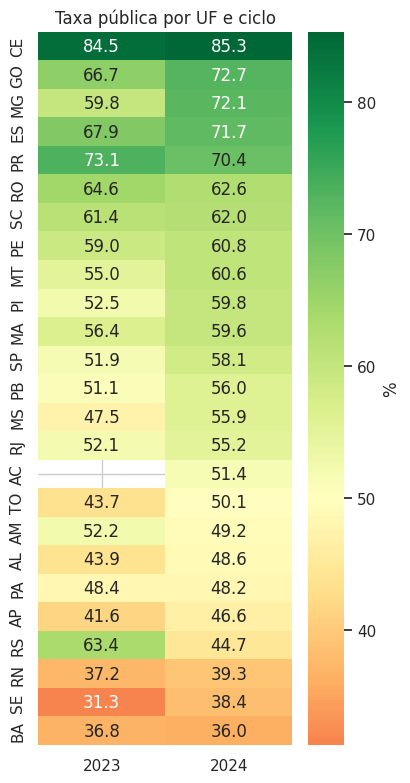

In [ ]:
plots.fig_heatmap_uf(gold, save=None)

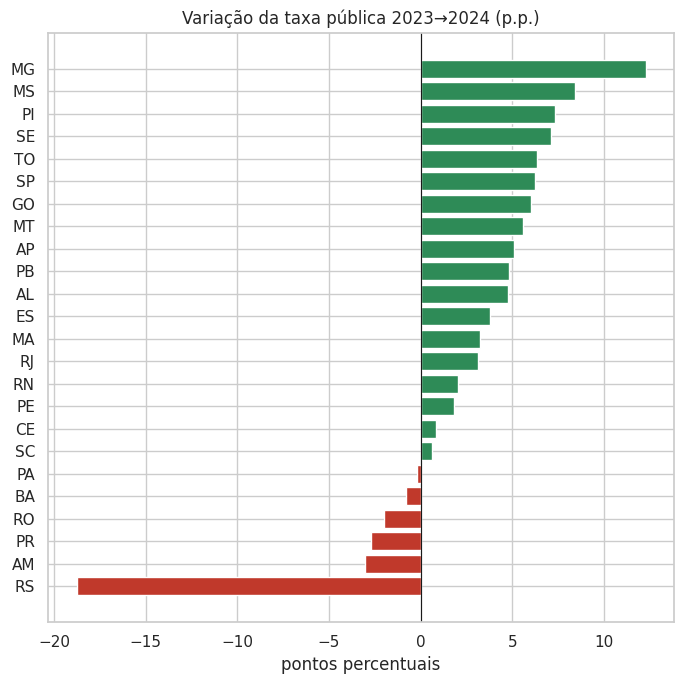

In [ ]:
plots.fig_variacao(gold, save=None)

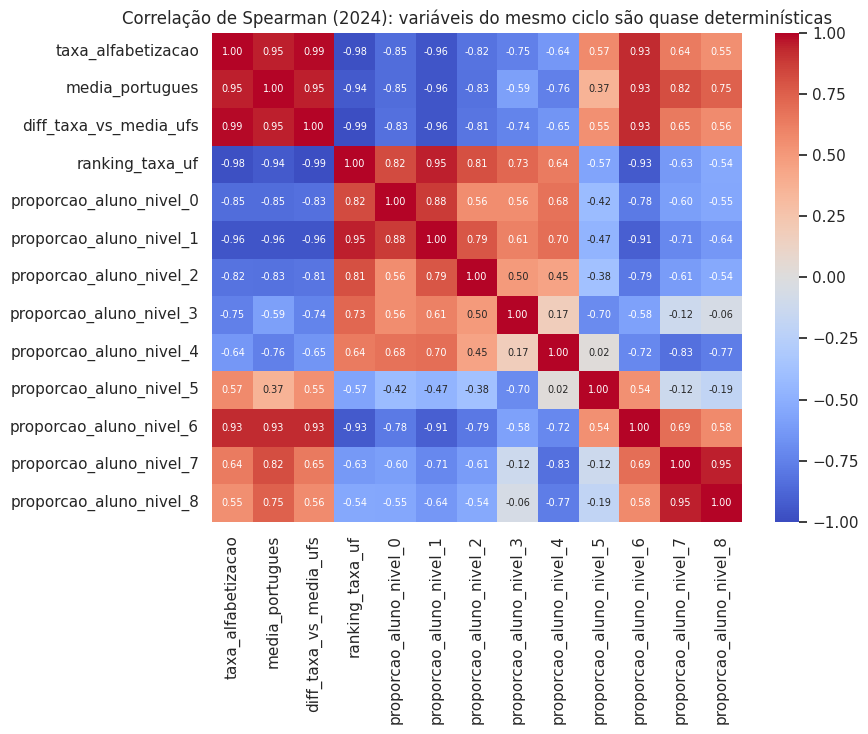

In [ ]:
plots.fig_correlacao(gold, save=None)

In [ ]:
plots.fig_vazamento(gold, save=None)
print("Spearman taxa x media_portugues:", round(gold[["taxa_alfabetizacao","media_portugues"]].corr(method="spearman").iloc[0,1], 3))

Spearman taxa x media_portugues: 0.96


In [ ]:
from src.evaluation.hypotheses import hypothesis_tests
ht = hypothesis_tests(gold)
ht[["hipotese", "teste", "n", "estatistica", "p_valor", "conclusao"]].round(4)

,hipotese,teste,n,estatistica,p_valor,conclusao
0,H1 regiões diferem (2023),Kruskal-Wallis,24,5.9662,0.2017,"não rejeita H0 (p>=0,05)"
1,H1 regiões diferem (2024),Kruskal-Wallis,25,4.6790,0.3218,"não rejeita H0 (p>=0,05)"
2,H2 persistência 2023→2024,Spearman (rho=0.85),24,0.8478,0.0000,"rejeita H0 (p<0,05)"
3,H3 mudança sistemática 2023→2024,Wilcoxon pareado,24,51.0000,0.0035,"rejeita H0 (p<0,05)"
4,H4 estadual ≠ municipal (2024),Wilcoxon pareado,24,93.0000,0.1074,"não rejeita H0 (p>=0,05)"
5,H5 estadual mais volátil que municipal,Wilcoxon pareado em |Δ|,22,98.0000,0.3705,"não rejeita H0 (p>=0,05)"


# 02 — Modelagem supervisionada, interpretabilidade e aplicação estratégica
**Tech Challenge Fase 3** — usa a camada Gold da Fase 2.

Esta parte mostra a pipeline de ML. O treino pesado (validação aninhada com 5 repetições) é feito por `python -m src.run_pipeline`; aqui reconstruímos os datasets, exibimos a pipeline sklearn, rodamos um exemplo e lemos os resultados gravados em `reports/`.

**Pergunta de modelagem:** dado o desempenho de uma UF/rede em **2023**, ela terá **taxa de alfabetização ≥ 50%** em **2024**? (classe 1 = sim; classe 0 = risco educacional).

In [ ]:
import sys, json
sys.path.append("..")            # raiz do repositório
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
from src.config import *
from src.preprocessing.load import load_gold

def mostrar_imagem(nome, largura=9):
    img = mpimg.imread(IMAGES / nome)
    h = largura * img.shape[0] / img.shape[1]
    fig = plt.figure(figsize=(largura, h)); plt.imshow(img); plt.axis("off")

from src.preprocessing.features import build_temporal_dataset, build_structural_dataset
from src.preprocessing.pipeline import build_model_pipeline
from src.modeling.train import candidates
from sklearn import set_config
set_config(display="text")

gold, _ = load_gold()
df = build_temporal_dataset(gold)
cfg = FEATURE_SETS["temporal"]
print("linhas:", len(df), "| prevalência da classe 1:", round(df[TARGET].mean(), 3))
print("lags ausentes (sem par em 2023):", int(df.lag_taxa.isna().sum()))
df[["sigla_uf", "rede_descricao", "taxa_alfabetizacao", TARGET, "lag_taxa", "lag_media", "lag_ranking_pct"]].head(8).round(2)

linhas: 74 | prevalência da classe 1: 0.662
lags ausentes (sem par em 2023): 4


,sigla_uf,rede_descricao,taxa_alfabetizacao,alfabetizacao_ok,lag_taxa,lag_media,lag_ranking_pct
0,GO,Estadual,83.66,1,76.59,763.67,0.18
1,GO,Municipal,72.73,1,66.72,752.13,0.17
2,GO,Pública (estadual + municipal),72.74,1,66.74,752.15,0.17
3,MS,Estadual,48.33,0,42.90,729.39,0.77
4,MS,Municipal,56.02,1,47.53,736.07,0.75
5,MS,Pública (estadual + municipal),55.87,1,47.45,735.95,0.75
6,MT,Estadual,46.75,0,48.02,738.00,0.73
7,MT,Municipal,61.03,1,55.43,747.32,0.46


In [ ]:
est, grid = candidates()["regressao_logistica"]
pipe = build_model_pipeline(est, cfg["numeric"], cfg["categorical"])
print(pipe)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(add_indicator=True,
                                                                                 strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['lag_taxa', 'lag_media',
                                                   'lag_diff_vs_media_ufs',
                                                   'lag_media_regiao',
                                                   'lag_ranking_pct']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                          

In [ ]:
for nome, (e, g) in candidates().items():
    print(f"{nome:22s} {type(e).__name__:28s} grade: {g}")

baseline_dummy         DummyClassifier              grade: {}
regressao_logistica    LogisticRegression           grade: {'model__C': [0.01, 0.1, 1.0, 10.0, 100.0]}
random_forest          RandomForestClassifier       grade: {'model__max_depth': [2, 4], 'model__min_samples_leaf': [2, 5]}
gradient_boosting      GradientBoostingClassifier   grade: {'model__n_estimators': [50, 150], 'model__max_depth': [1, 2], 'model__learning_rate': [0.05, 0.1]}


In [ ]:
from src.evaluation.metrics import compute_metrics
from src.modeling.train import holdout_eval
X, y, grp = df[cfg["numeric"] + cfg["categorical"]], df[TARGET].values, df["grupo"].values
h = holdout_eval("regressao_logistica", est, grid, X, y, grp, cfg["numeric"], cfg["categorical"])
print("UFs no teste (nunca vistas no treino):", h["ufs_teste"])
print("n treino / teste:", h["n_treino"], "/", h["n_teste"])
print("melhores hiperparâmetros (CV interna):", h["melhores_params"])
{k: round(v, 3) for k, v in h["metricas_teste"].items()}

UFs no teste (nunca vistas no treino): ['AL', 'BA', 'ES', 'MT', 'PB', 'RJ', 'TO']
n treino / teste: 54 / 20
melhores hiperparâmetros (CV interna): {'model__C': 0.01}


{'roc_auc': 0.912,
 'pr_auc': 0.963,
 'f1': 0.788,
 'f1_risco': 0.0,
 'bal_acc': 0.5,
 'brier': 0.182}

In [ ]:
comp = pd.read_csv(REPORTS / "comparacao_modelos.csv")
cols = ["conjunto", "modelo", "n", "roc_auc_media", "roc_auc_desvio", "pr_auc_media", "f1_risco_media", "bal_acc_media", "brier_media"]
comp[cols].round(3)

,conjunto,modelo,n,roc_auc_media,roc_auc_desvio,pr_auc_media,f1_risco_media,bal_acc_media,brier_media
0,estrutural,baseline_dummy,144,0.312,0.071,0.567,0.000,0.500,0.244
1,estrutural,regressao_logistica,144,0.511,0.076,0.719,0.137,0.445,0.251
2,estrutural,random_forest,144,0.554,0.082,0.757,0.218,0.473,0.235
3,estrutural,gradient_boosting,144,0.571,0.068,0.756,0.299,0.498,0.252
4,temporal,baseline_dummy,74,0.309,0.055,0.576,0.000,0.500,0.240
5,temporal,regressao_logistica,74,0.817,0.015,0.864,0.362,0.614,0.179
6,temporal,random_forest,74,0.793,0.019,0.802,0.742,0.803,0.138
7,temporal,gradient_boosting,74,0.790,0.027,0.810,0.775,0.825,0.136
8,temporal,baseline_persistencia,74,0.882,0.000,0.924,0.800,0.849,0.179
9,temporal_parcimonioso,baseline_dummy,74,0.309,0.055,0.576,0.000,0.500,0.240


In [ ]:
mostrar_imagem("06_comparacao_modelos.png", 10)

In [ ]:
ho = pd.read_csv(REPORTS / "holdout_teste.csv")
ho[ho.conjunto.str.startswith("temporal")][["conjunto", "modelo", "n_teste", "ufs_teste", "teste_roc_auc", "teste_f1_risco", "teste_bal_acc"]].round(3)

,conjunto,modelo,n_teste,ufs_teste,teste_roc_auc,teste_f1_risco,teste_bal_acc
4,temporal,baseline_dummy,20,"AL,BA,ES,MT,PB,RJ,TO",0.500,0.0,0.500
5,temporal,regressao_logistica,20,"AL,BA,ES,MT,PB,RJ,TO",0.912,0.0,0.500
6,temporal,random_forest,20,"AL,BA,ES,MT,PB,RJ,TO",0.934,0.8,0.852
7,temporal,gradient_boosting,20,"AL,BA,ES,MT,PB,RJ,TO",0.857,0.8,0.852
8,temporal_parcimonioso,baseline_dummy,20,"AL,BA,ES,MT,PB,RJ,TO",0.500,0.0,0.500
9,temporal_parcimonioso,regressao_logistica,20,"AL,BA,ES,MT,PB,RJ,TO",0.934,0.0,0.500


In [ ]:
mostrar_imagem("07_roc_temporal.png", 6)
mostrar_imagem("08_matriz_confusao.png", 4.5)

In [ ]:
print("Permutação em bloco (queda de AUC em folds não vistos):")
pd.read_csv(REPORTS / "importancia_grupos.csv", index_col=0).round(4)

Permutação em bloco (queda de AUC em folds não vistos):


,queda_auc_media,desvio
desempenho anterior (todas as lag_*),0.3493,0.1980
rede,-0.0031,0.0099
região,-0.0052,0.0125


In [ ]:
print("Permutação variável a variável:")
pd.read_csv(REPORTS / "importancia_permutacao.csv", index_col=0).round(4)

Permutação variável a variável:


,queda_auc_media,desvio
lag_media,0.0402,0.0606
lag_diff_vs_media_ufs,0.0197,0.0357
lag_taxa,0.0194,0.0310
lag_ranking_pct,0.0116,0.0227
rede_descricao,-0.0020,0.0076
regiao,-0.0048,0.0137
lag_media_regiao,-0.0158,0.0412


In [ ]:
mostrar_imagem("13_importancia_grupos.png", 7)

In [ ]:
pd.read_csv(REPORTS / "clusters_perfil.csv").round(2)

,cluster,taxa_publica_2023,taxa_publica_2024,variacao_pp,gap_estadual_municipal_2024,n_ufs,ufs
0,Alto desempenho,69.40,65.01,-4.39,-3.34,5,"CE, PR, RO, RS, SC"
1,Intermediário,56.70,59.90,4.05,12.35,11,"AC, AM, ES, GO, MA, MG, PA, PE, PI, RJ, SP"
2,Baixo desempenho,43.12,47.93,4.81,-4.16,9,"AL, AP, BA, MS, MT, PB, RN, SE, TO"


In [ ]:
mostrar_imagem("10_clusters_ufs.png", 8)

### Quais UFs/redes têm maior risco de não atingir o limiar na próxima edição?

In [ ]:
risco = pd.read_csv(REPORTS / "risco_proxima_edicao.csv")
pub = risco[risco.rede == 5][["sigla_uf", "regiao", "taxa_alfabetizacao", "prob_risco", "faixa_risco"]]
pub.rename(columns={"taxa_alfabetizacao": "taxa_2024"}).round(3).reset_index(drop=True)

,sigla_uf,regiao,taxa_2024,prob_risco,faixa_risco
0,BA,Nordeste,35.96,0.529,alto
1,SE,Nordeste,38.39,0.516,alto
2,RN,Nordeste,39.29,0.492,médio
3,RS,Sul,44.67,0.440,médio
4,PA,Norte,48.20,0.430,médio
5,AP,Norte,46.62,0.428,médio
6,AL,Nordeste,48.63,0.413,médio
7,AM,Norte,49.17,0.413,médio
8,TO,Norte,50.07,0.386,médio
9,AC,Norte,51.38,0.382,médio


In [ ]:
mostrar_imagem("11_risco_proxima_edicao.png", 7.5)

### Quão confiáveis são as faixas de risco? (previsões fora da amostra em 2024)

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
oof = pd.read_csv(REPORTS / "risco_oof_2024.csv")
yr = 1 - oof[TARGET].values; pr = oof.prob_risco_oof.values
print("ROC AUC para detectar risco (OOF):", round(roc_auc_score(yr, pr), 3))
linhas = []
for t in [0.25, 0.35, 0.40, 0.50]:
    pred = (pr >= t).astype(int)
    linhas.append({"limiar_prob_risco": t, "precisao": precision_score(yr, pred), "recall": recall_score(yr, pred),
                   "f1": f1_score(yr, pred), "n_sinalizadas": int(pred.sum())})
pd.DataFrame(linhas).round(2)

ROC AUC para detectar risco (OOF): 0.821


,limiar_prob_risco,precisao,recall,f1,n_sinalizadas
0,0.25,0.49,0.84,0.62,43
1,0.35,0.66,0.76,0.70,29
2,0.40,0.79,0.76,0.78,24
3,0.50,1.00,0.36,0.53,9
